In [19]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from pathlib import Path

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.5 MB 7.9 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 7.8 MB/s eta 0:00:01
   --------------- ------------------------ 3.7/9.5 MB 5.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 7.2 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 7.2 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 7.2 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.5 MB 3.6 MB/s eta 0:00:02
   ----------------------------- ---------- 7.1/9.5 MB 4.1 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 4.1 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 3.9 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 3.5 MB/s eta 0:00:01
   -----------------------

In [7]:
data_dir = Path(r"C:\Users\dmitry kuzmin\Desktop\sentiment-analysis-tg-news\data\training")

train = pd.read_csv(data_dir / "train.csv")
dev = pd.read_csv(data_dir / "dev.csv")
test = pd.read_csv(data_dir / "test.csv")

In [9]:
for name, df in [("train", train), ("dev", dev), ("test", test)]:
    print(f"{name}: {df.shape}")
    print(df["label"].value_counts(normalize=True))
    print()

train: (2938, 2)
label
1    0.660994
0    0.339006
Name: proportion, dtype: float64

dev: (424, 2)
label
1    0.639151
0    0.360849
Name: proportion, dtype: float64

test: (867, 2)
label
1    0.67128
0    0.32872
Name: proportion, dtype: float64



In [10]:
train.head()

,label,text
0,0,Досудебное расследование по факту покупки ЕНПФ...
1,0,Медики рассказали о состоянии пострадавшего му...
2,0,"Прошел почти год , как железнодорожным операто..."
3,0,По итогам 12 месяцев 2016 года на территории р...
4,0,Астана . 21 ноября . Kazakhstan Today - Агентс...


In [17]:
x_train = train["text"].fillna("")
y_train = train["label"]

x_dev = dev["text"].fillna("")
y_dev = dev["label"]

vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

x_train_tfidf = vectorizer.fit_transform(x_train)
x_dev_tfidf = vectorizer.transform(x_dev)

print(x_train_tfidf.shape)
print(x_dev_tfidf.shape)

(2938, 50000)
(424, 50000)


In [26]:
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(x_train_tfidf, y_train)
y_pred = model.predict(x_dev_tfidf)

print(classification_report(y_dev, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9013    0.8954    0.8984       153
           1     0.9412    0.9446    0.9429       271

    accuracy                         0.9269       424
   macro avg     0.9212    0.9200    0.9206       424
weighted avg     0.9268    0.9269    0.9268       424



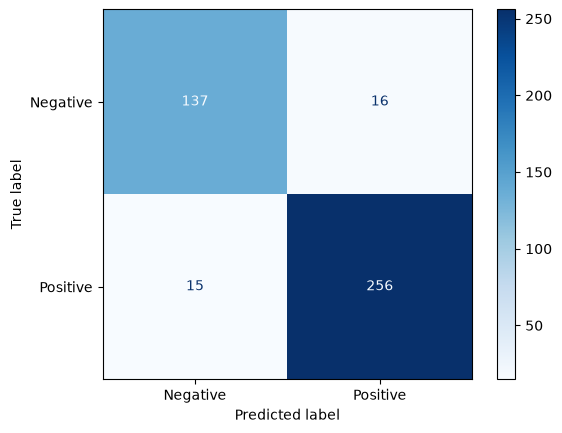

In [23]:
ConfusionMatrixDisplay.from_predictions(y_dev, y_pred, display_labels=["Negative", "Positive"], cmap="Blues")

In [25]:
import joblib

joblib.dump(model, "logreg.pkl")
joblib.dump(vectorizer, "tfidf.pkl")

['tfidf.pkl']